# 08a – Streifenkorrektur (Destriping) für NGC 6720

**Was:** Zeilenstreifen (Ausleserauschen der Detektoren, „1/f-Rauschen“) in den i2d-Bildern **vor** der Registrierung entfernen.

**Warum:** Die kurze Belichtung (483 s) macht die Streifen in F162M und F212N deutlich sichtbar. Ein Hintergrundabzug zieht nur *einen* Wert pro Filter ab und kann kein Muster entfernen, das sich von Zeile zu Zeile ändert. In den Originaldateien laufen die Streifen entlang der Bildzeilen; nach der Reprojektion (≈ 45° gedreht) liegen sie schräg. Deshalb hier, vorher.

**Methode** (Modul `astropipe.clean`):
1. Hintergrundmaske: Nebel und Sterne (> Median + 3σ) großzügig ausmaskieren (+15 px)
2. Pro Zeile: Median der Hintergrundpixel → Zeilenprofil
3. Langsamen Anteil (gleitender Median über 51 Zeilen) behalten – das sind echte Verläufe
4. Nur den schnellen Anteil (die Streifen) abziehen

**Mikroskopie-Analogie:** Zeilenweise Korrektur von Scan-Artefakten (Banding) beim Zeilenscanner.

**Kontrolle:** Das Differenzbild *vorher − nachher* darf nur Streifen zeigen, keine Nebelstruktur.

**Einschränkung:** Näherung auf Ebene des fertigen i2d-Bildes; die saubere Korrektur geschieht früher, pro Detektor und Ausleseverstärker in den Einzelaufnahmen.

**Ergebnis:** _(nach dem Ausführen eintragen)_

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

from astropipe import bands, clean

ROOT = Path("..")
RAW = ROOT / "data" / "ngc6720_nircam"
OUT = ROOT / "data" / "ngc6720_nircam_destriped"
I2D = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(RAW.glob("*_i2d.fits"))}
BANDS = bands.sort_bands(I2D)
print(BANDS)

['F162M', 'F212N', 'F300M', 'F335M']


## 1. Diagnose: Wie stark sind Zeilen- und Spaltenstreifen in jedem Filter?

Die „Streifenstärke“ ist die Standardabweichung des Streifenprofils. Zum Vergleich das Pixelrauschen (robust, aus den Hintergrundpixeln). Verhältnis Zeilen/Spalten ≫ 1 heißt: Streifen entlang der Zeilen.

In [7]:
sci, bgmask = {}, {}
print(f"{'band':<6}{'pixel noise':>12}{'rows':>9}{'cols':>9}{'rows/cols':>11}")
for b in BANDS:
    sci[b] = fits.getdata(I2D[b], extname="SCI").astype(np.float32)
    bgmask[b] = clean.background_mask(sci[b])
    v = sci[b][bgmask[b]]
    noise = 1.4826 * np.median(np.abs(v - np.median(v)))
    r, c = clean.stripe_strength(sci[b], bgmask[b], "rows"), clean.stripe_strength(sci[b], bgmask[b], "cols")
    r128 = clean.stripe_strength(sci[b], bgmask[b], "rows", segment=128)
    print(f"{b:<6}{noise:12.4f}{r:9.4f}{c:9.4f}{r / c:11.2f}   rows per 128-px block: {r128:.4f}")

band   pixel noise     rows     cols  rows/cols
F162M       0.2497   0.0297   0.0085       3.50   rows per 128-px block: 0.0935
F212N       2.3033   0.2748   0.0898       3.06   rows per 128-px block: 0.7902
F300M       0.0666   0.0121   0.0042       2.88   rows per 128-px block: 0.0227
F335M       0.0971   0.0118   0.0055       2.14   rows per 128-px block: 0.0224


## 2. Hintergrundmaske prüfen

Weiß = als Hintergrund genutzt, schwarz = maskiert (Nebel, Sterne, NaN). Der Nebel und die hellen Bögen müssen schwarz sein; sonst würde ihre Helligkeit als „Streifen“ interpretiert.

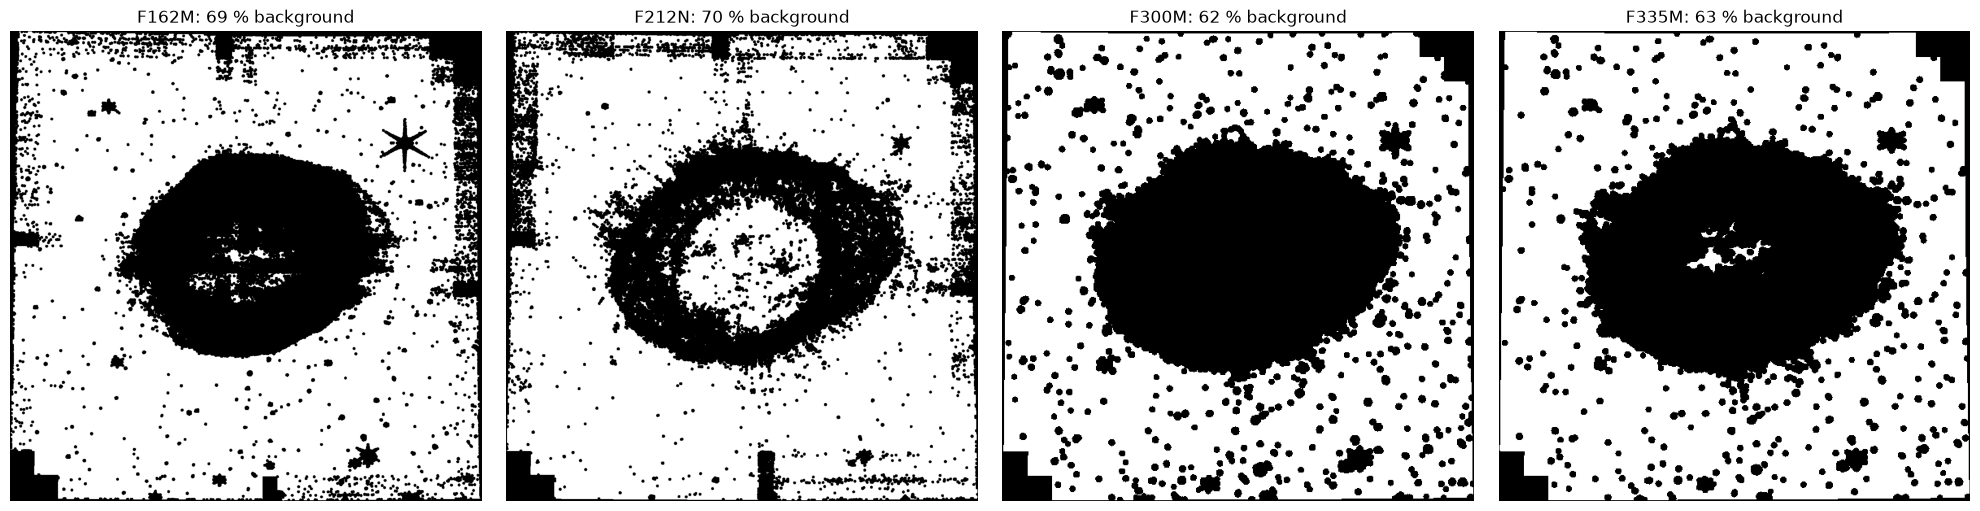

In [8]:
fig, axes = plt.subplots(1, len(BANDS), figsize=(5 * len(BANDS), 5))
for ax, b in zip(axes, BANDS):
    ax.imshow(bgmask[b][::4, ::4], origin="lower", cmap="gray")
    ax.set_title(f"{b}: {100 * bgmask[b].mean():.0f} % background")
    ax.axis("off")
plt.tight_layout()

## 3. Korrektur und Kontrolle

`DESTRIPE` legt fest, welche Filter korrigiert werden – nach der Tabelle in Schritt 1 (deutliche Streifen, Verhältnis Zeilen/Spalten klar > 1). Für jeden: Ausschnitt vorher, nachher und das Differenzbild.

F162M: residual stripes per 128-px block 0.0935 -> 0.0663
F212N: residual stripes per 128-px block 0.7902 -> 0.5489
F300M: residual stripes per 128-px block 0.0227 -> 0.0146
F335M: residual stripes per 128-px block 0.0224 -> 0.0162


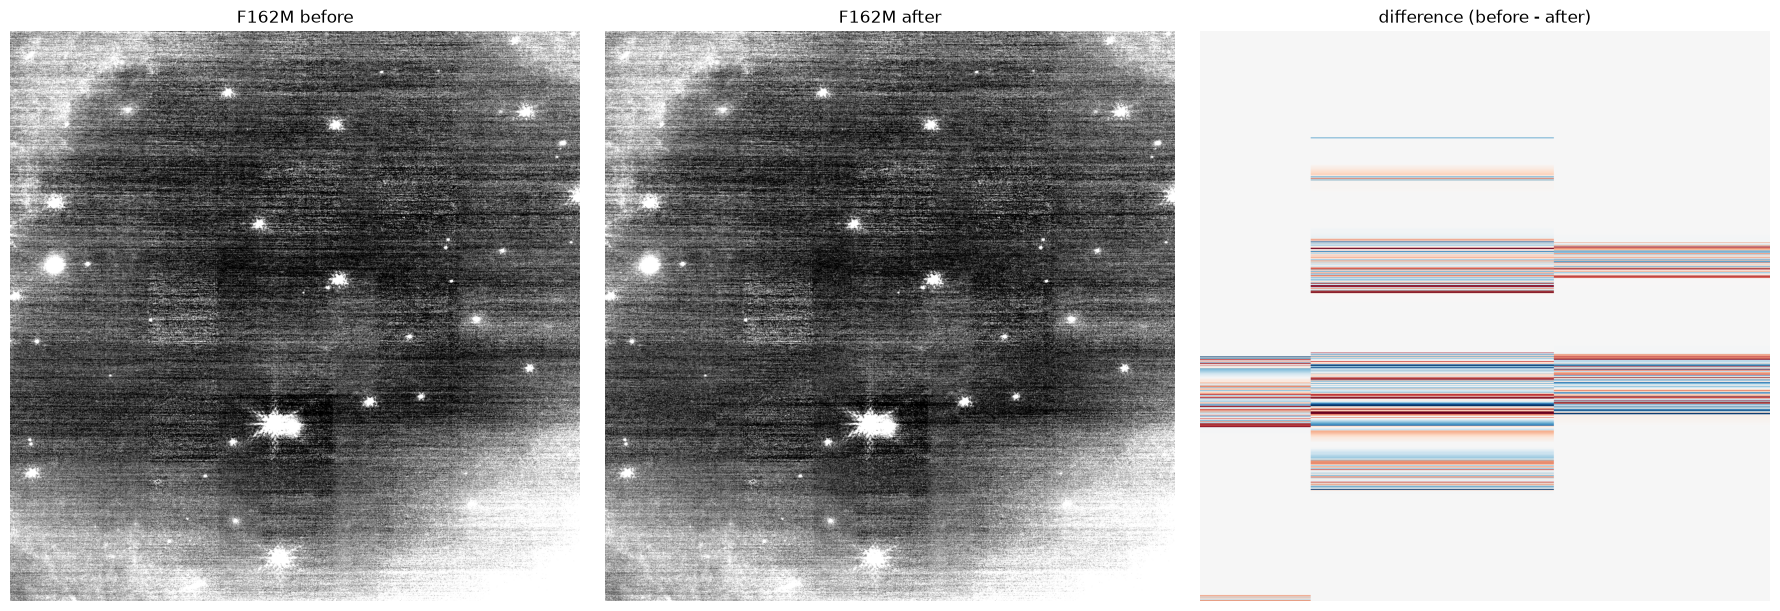

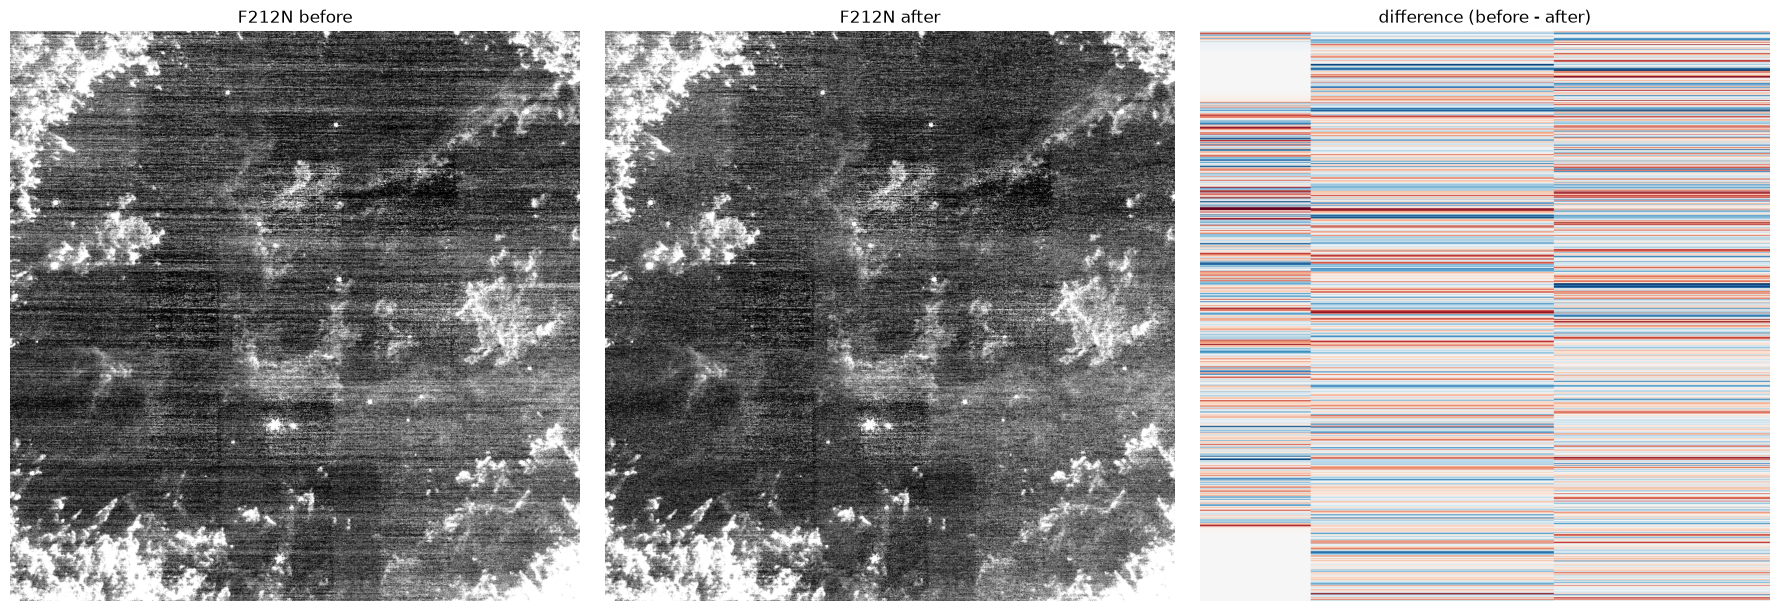

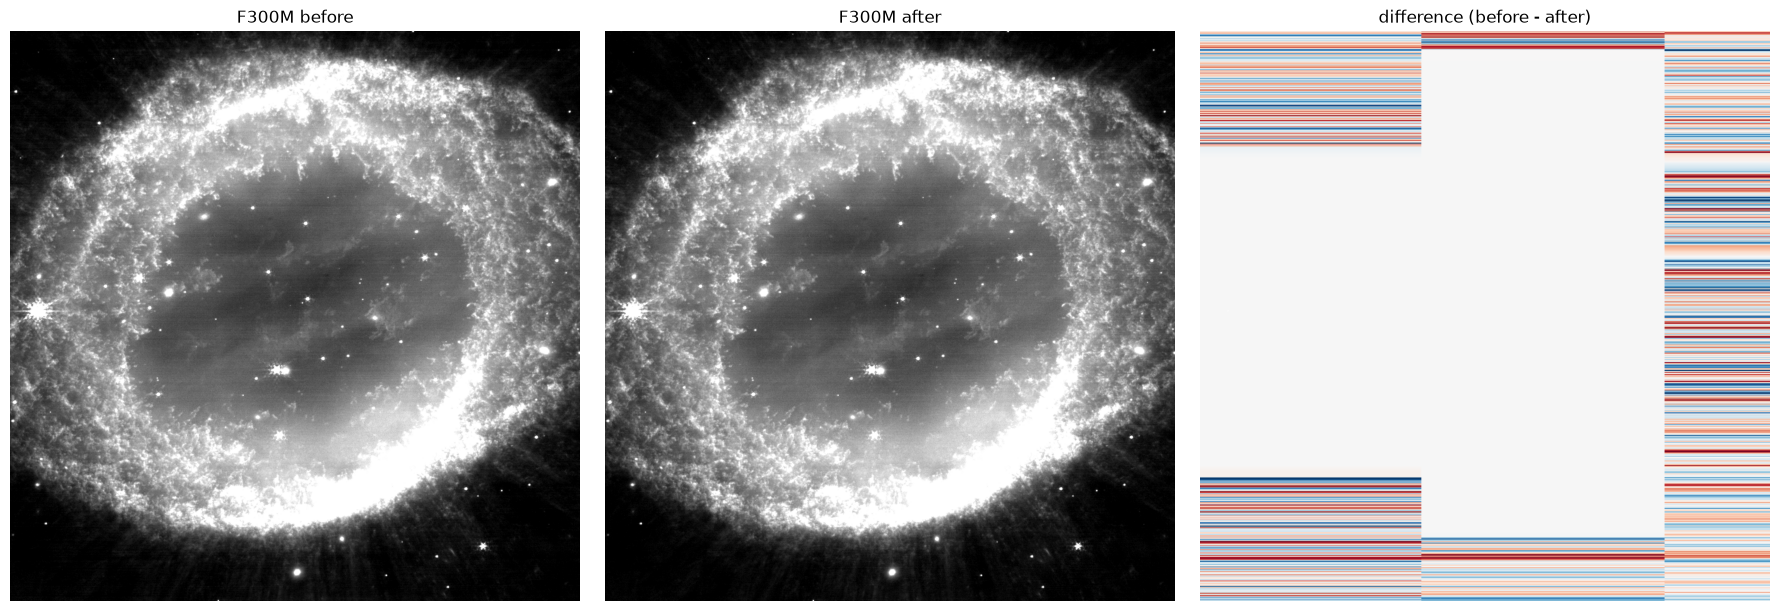

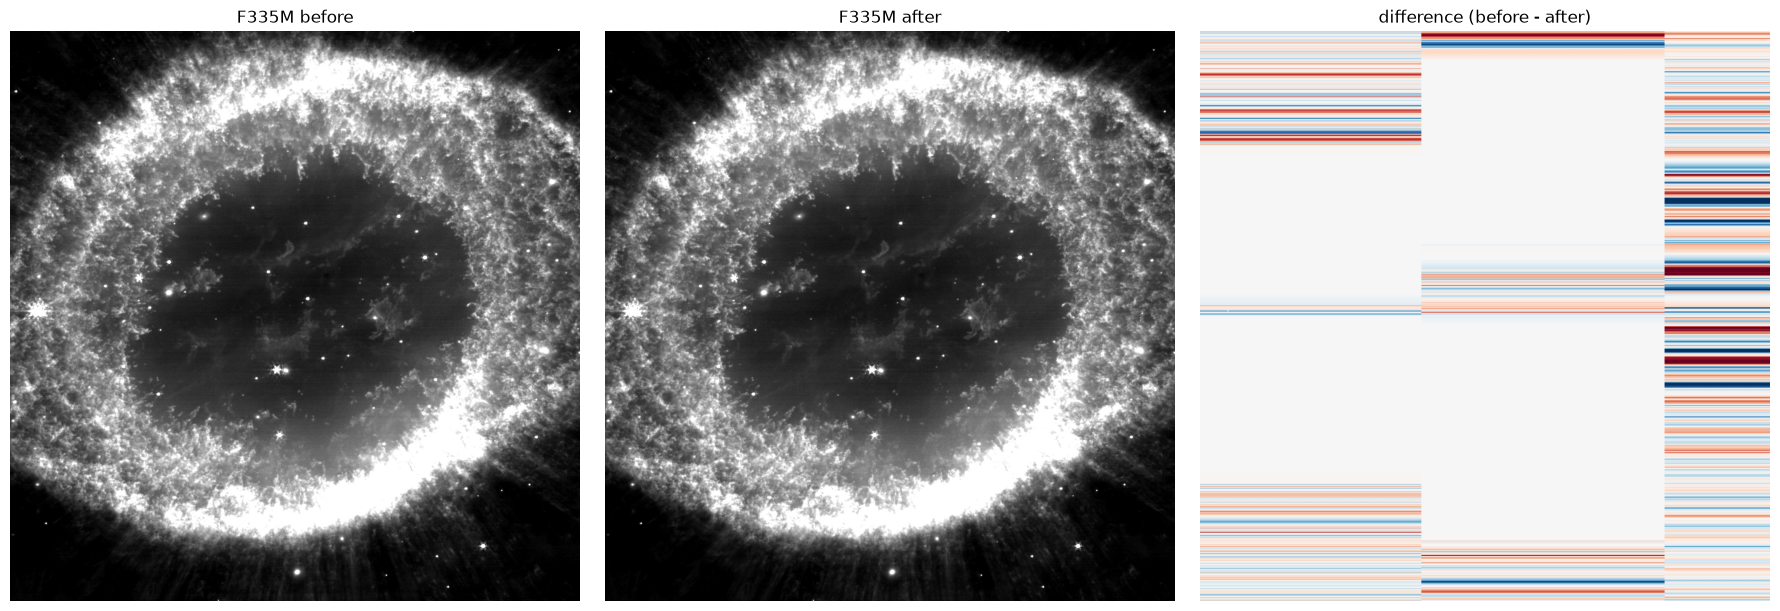

In [9]:
DESTRIPE = ["F162M", "F212N", "F300M", "F335M"]
SMOOTH, SEG = 51, 512

cleaned, profiles = {}, {}
for b in DESTRIPE:
    cleaned[b], profiles[b], _ = clean.destripe(sci[b], "rows", smooth=SMOOTH, segment=SEG)
    before = clean.stripe_strength(sci[b], bgmask[b], "rows", SMOOTH, segment=128)
    after = clean.stripe_strength(cleaned[b], bgmask[b], "rows", SMOOTH, segment=128)
    print(f"{b}: residual stripes per 128-px block {before:.4f} -> {after:.4f}")

def show_triplet(b, sl):
    a, c = sci[b][sl], cleaned[b][sl]
    lo, hi = np.nanpercentile(a, [5, 95])
    d = a - c
    dl = np.nanpercentile(np.abs(d), 99)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(a, origin="lower", cmap="gray", vmin=lo, vmax=hi); axes[0].set_title(f"{b} before")
    axes[1].imshow(c, origin="lower", cmap="gray", vmin=lo, vmax=hi); axes[1].set_title(f"{b} after")
    axes[2].imshow(d, origin="lower", cmap="RdBu", vmin=-dl, vmax=dl); axes[2].set_title("difference (before - after)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()

for b in DESTRIPE:
    ny, nx = sci[b].shape
    show_triplet(b, np.s_[ny // 2 - 600:ny // 2 + 600, nx // 2 - 600:nx // 2 + 600])   # centre incl. nebula

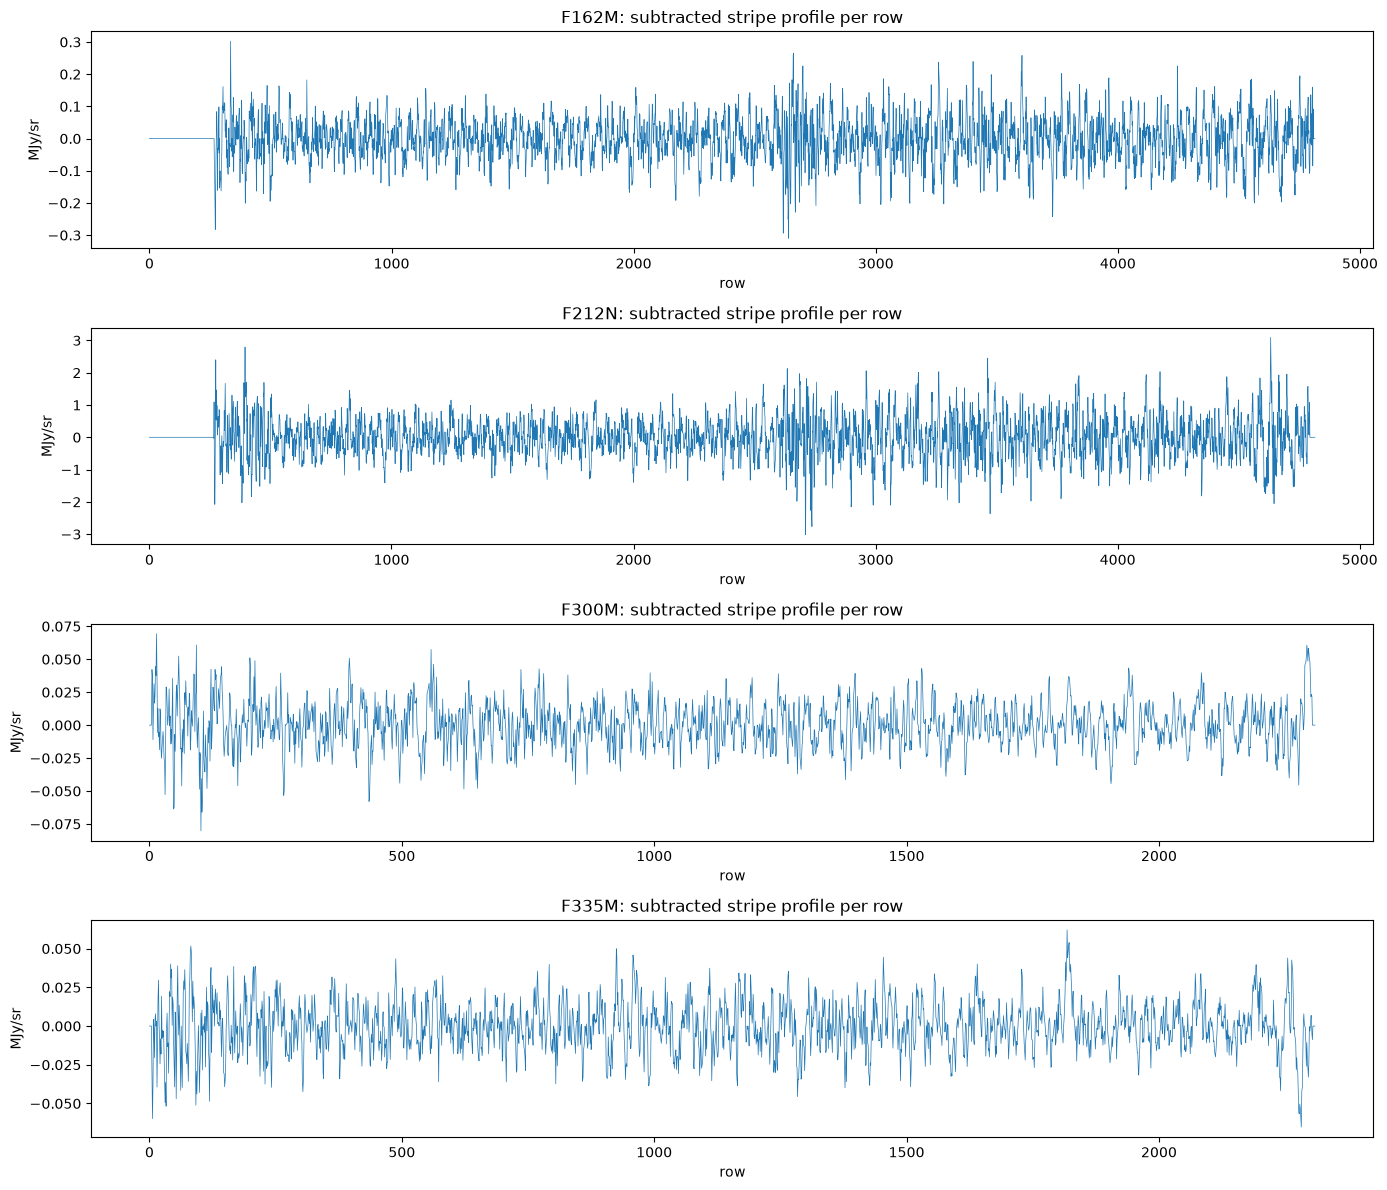

In [10]:
fig, axes = plt.subplots(len(DESTRIPE), 1, figsize=(14, 3 * len(DESTRIPE)), squeeze=False)
for ax, b in zip(axes[:, 0], DESTRIPE):
    ax.plot(profiles[b] if profiles[b].ndim == 1 else profiles[b][:, 0], lw=0.5)
    ax.set_title(f"{b}: subtracted stripe profile per row")
    ax.set_xlabel("row"); ax.set_ylabel("MJy/sr")
plt.tight_layout()

## 4. Speichern

Bereinigte Bilder (PRIMARY + SCI mit Original-Headern und HISTORY-Vermerk) nach `data/ngc6720_nircam_destriped/`. Notebook 08 verwendet sie dann für die korrigierten Filter.

In [11]:
for b in DESTRIPE:
    note = f"astropipe.clean.destripe(axis='rows', smooth={SMOOTH}, segment={SEG}, nsigma=3, grow_px=15)"
    p = clean.write_cleaned_i2d(I2D[b], OUT / I2D[b].name.replace("_i2d", "_destriped_i2d"), cleaned[b], note)
    print(p)

../data/ngc6720_nircam_destriped/jw01558-o005_t001_nircam_f150w2-f162m_destriped_i2d.fits
../data/ngc6720_nircam_destriped/jw01558-o005_t001_nircam_clear-f212n_destriped_i2d.fits
../data/ngc6720_nircam_destriped/jw01558-o005_t001_nircam_clear-f300m_destriped_i2d.fits
../data/ngc6720_nircam_destriped/jw01558-o005_t001_nircam_clear-f335m_destriped_i2d.fits


## Fazit

- **Diagnose:** In allen vier Filtern laufen die Streifen entlang der Zeilen der i2d-Bilder (Zeilen/Spalten 2,1–3,5). Bezogen auf das Pixelrauschen sind sie überall ähnlich stark; am deutlichsten sichtbar in F212N und F162M.
- **Maske:** Nebel, Ring und Sterne zuverlässig ausmaskiert; 62–70 % der Pixel als Hintergrund nutzbar.
- **Version 1 (ganze Zeile):** Differenzbild zeigt nur Streifen (gut), aber im Bild blieben deutlich Streifen. Die Kennzahl (Profil über die ganze Zeile) war zu optimistisch, weil sie mit derselben Methode misst, mit der korrigiert wird. Viele Streifen laufen nicht über die ganze Breite (getrennte Ausleseverstärker, mehrere versetzte Aufnahmen).
- **Version 2 (Abschnitte à 512 px), verwendet:** Reststreifen pro 128-px-Block um 28–36 % gesenkt (F212N 0,79 → 0,55). F212N sichtbar ruhiger. Differenzbild: keine Nebelstruktur, aber senkrechte Kanten an den Abschnittsgrenzen; Abschnitte, die fast ganz vom Nebel bedeckt sind, bleiben unkorrigiert.
- **Nicht behoben:** feine Reststreifen und rechteckige Helligkeitsblöcke (Detektorbereiche). Eine saubere Korrektur müsste in den Einzelaufnahmen pro Detektor/Verstärker ansetzen.
- **Entscheidung:** korrigierte Versionen aller vier Filter in Notebook 08 verwenden (Schalter `USE_DESTRIPED`), Wirkung im Farbbild prüfen.